<a href="https://colab.research.google.com/github/Anil-Pradhan-web/Learn_ML/blob/main/Assignment_1_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📘 CSE 3967: Machine Learning Concepts 1
## Assignment 1: Hands-On Exercises & Home Assignments
---
**Student Details**: B.Tech CSE (3rd Year)  
**Course Code**: CSE 3967 (0L - 4P)  
**Topics Covered**:
- 2D Array & Matrix Algebra (`numpy`)
- Data Wrangling & Aggregation (`pandas`)
- Statistical Data Visualization (`matplotlib.pyplot`)
- Synthetic Regression Modeling & Scikit-Learn Pipelines (`scikit-learn`)
- Mathematical Dataset Formulation & Residual Error Diagnostics on `Simple_House_Price.csv`


### 📦 0. Setup & Global Configuration


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set inline plotting styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("All required libraries loaded successfully!")


All required libraries loaded successfully!


# ========================================================
# 🚀 PART 1: HANDS-ON EXERCISES (Questions 1 to 6)
# ========================================================


## 📌 Question 1: NumPy 2D Array Operations
Create a 2D array of shape `(3, 3)`:
```python
[[10, -20, 30],
 [40, -50, 60],
 [70,  80, -90]]
```
Calculate:
1. Mean of each row (`axis=1`)
2. Mean of each column (`axis=0`)
3. Standard deviation of each row (`axis=1`)
4. Maximum value of each column (`axis=0`)
5. Minimum value of each row (`axis=1`)


In [15]:
data = np.array([
    [10, -20, 30],
    [40, -50, 60],
    [70,  80, -90]
])

print("Original Array:")
print(data)
print("-" * 50)

# 1. Mean of each row
row_mean = np.mean(data, axis=1)
print("1. Mean of each row (axis=1):", row_mean)

# 2. Mean of each column
col_mean = np.mean(data, axis=0)
print("2. Mean of each column (axis=0):", col_mean)

# 3. Standard deviation of each row
row_std = np.std(data, axis=1)
print("3. Standard deviation of each row (axis=1):", np.round(row_std, 2))

# 4. Maximum value of each column
col_max = np.max(data, axis=0)
print("4. Maximum value of each column (axis=0):", col_max)

# 5. Minimum value of each row
row_min = np.min(data, axis=1)
print("5. Minimum value of each row (axis=1):", row_min)


Original Array:
[[ 10 -20  30]
 [ 40 -50  60]
 [ 70  80 -90]]
--------------------------------------------------
1. Mean of each row (axis=1): [ 6.66666667 16.66666667 20.        ]
2. Mean of each column (axis=0): [40.          3.33333333  0.        ]
3. Standard deviation of each row (axis=1): [20.55 47.84 77.89]
4. Maximum value of each column (axis=0): [70 80 60]
5. Minimum value of each row (axis=1): [-20 -50 -90]


## 📌 Question 2: Matrix Algebra Operations
Given matrices:
$$A = \begin{bmatrix} 2 & -4 \\ -6 & 8 \end{bmatrix}, \quad B = \begin{bmatrix} 1 & -3 \\ -5 & -7 \end{bmatrix}$$
Calculate:
1. Addition ($A + B$)
2. Subtraction ($A - B$)
3. Matrix Multiplication ($A \cdot B$)
4. Transpose of $A$ ($A^T$)
5. Determinant of $A$ ($\det(A)$)
6. Inverse of $A$ ($A^{-1}$)


In [16]:
A = np.array([[2, -4], [-6, 8]])
B = np.array([[1, -3], [-5, -7]])

print("Matrix A:")
print(A)
print("\nMatrix B:")
print(B)
print("=" * 45)

# 1. Addition
print("1. A + B:")
print(A + B)

# 2. Subtraction
print("\n2. A - B:")
print(A - B)

# 3. Matrix Multiplication
print("\n3. A · B (Matrix Multiplication):")
print(np.dot(A, B))

# 4. Transpose
print("\n4. Transpose of A (A^T):")
print(A.T)

# 5. Determinant
det_A = np.linalg.det(A)
print(f"\n5. Determinant of A: {det_A:.2f}")

# 6. Inverse
inv_A = np.linalg.inv(A)
print("\n6. Inverse of A (A^-1):")
print(inv_A)


Matrix A:
[[ 2 -4]
 [-6  8]]

Matrix B:
[[ 1 -3]
 [-5 -7]]
1. A + B:
[[  3  -7]
 [-11   1]]

2. A - B:
[[ 1 -1]
 [-1 15]]

3. A · B (Matrix Multiplication):
[[ 22  22]
 [-46 -38]]

4. Transpose of A (A^T):
[[ 2 -6]
 [-4  8]]

5. Determinant of A: -8.00

6. Inverse of A (A^-1):
[[-1.   -0.5 ]
 [-0.75 -0.25]]


## 📌 Question 3: Pandas DataFrame Creation & Analysis
Create a product sales dictionary, convert it into a DataFrame, and perform:
1. Print DataFrame, column names, and shape
2. First three rows
3. Specific columns (`Products`, `Price`)
4. Summary statistics for `Sales` (mean, median, std, min, max)
5. Filter products where `Profit` > 120,000
6. Sort DataFrame by `Profit` descending


In [17]:
product_data = {
    'Products': ['Laptop', 'Smartphone', 'Tablet', 'Smartwatch', 'Headphones', 'Monitor'],
    'Price': [60000, 35000, 25000, 15000, 8000, 20000],
    'Sales': [150, 400, 220, 350, 500, 180],
    'Profit': [180000, 280000, 110000, 105000, 80000, 90000]
}

df_products = pd.DataFrame(product_data)

print("--- 1. Full DataFrame ---")
print(df_products)
print("\nColumns:", list(df_products.columns))
print("Shape:", df_products.shape)

print("\n--- 2. First Three Rows ---")
print(df_products.head(3))

print("\n--- 3. Specific Columns (Products, Price) ---")
print(df_products[['Products', 'Price']])

print("\n--- 4. Summary Statistics for Sales ---")
sales_stats = {
    'Mean': df_products['Sales'].mean(),
    'Median': df_products['Sales'].median(),
    'Std Dev': df_products['Sales'].std(),
    'Min': df_products['Sales'].min(),
    'Max': df_products['Sales'].max()
}
for k, v in sales_stats.items():
    print(f"{k:8s}: {v:.2f}")

print("\n--- 5. Products with Profit > 120,000 ---")
high_profit_df = df_products[df_products['Profit'] > 120000]
print(high_profit_df[['Products', 'Profit']])

print("\n--- 6. DataFrame Sorted by Profit (Descending) ---")
sorted_df = df_products.sort_values(by='Profit', ascending=False)
print(sorted_df)


--- 1. Full DataFrame ---
     Products  Price  Sales  Profit
0      Laptop  60000    150  180000
1  Smartphone  35000    400  280000
2      Tablet  25000    220  110000
3  Smartwatch  15000    350  105000
4  Headphones   8000    500   80000
5     Monitor  20000    180   90000

Columns: ['Products', 'Price', 'Sales', 'Profit']
Shape: (6, 4)

--- 2. First Three Rows ---
     Products  Price  Sales  Profit
0      Laptop  60000    150  180000
1  Smartphone  35000    400  280000
2      Tablet  25000    220  110000

--- 3. Specific Columns (Products, Price) ---
     Products  Price
0      Laptop  60000
1  Smartphone  35000
2      Tablet  25000
3  Smartwatch  15000
4  Headphones   8000
5     Monitor  20000

--- 4. Summary Statistics for Sales ---
Mean    : 300.00
Median  : 285.00
Std Dev : 138.42
Min     : 150.00
Max     : 500.00

--- 5. Products with Profit > 120,000 ---
     Products  Profit
0      Laptop  180000
1  Smartphone  280000

--- 6. DataFrame Sorted by Profit (Descending) ---
   

## 📌 Question 4: Matplotlib Visualizations
Generate all 6 required statistical charts from `df_products`:
1. **Scatter Plot**: Price vs. Sales
2. **Line Plot**: Sales and Profit across products
3. **Bar Chart**: Profit per product with numeric value annotations
4. **Bar Chart**: Profit per Unit of Sales
5. **Pie Chart**: Sales contribution by product
6. **Histogram**: Sales distribution


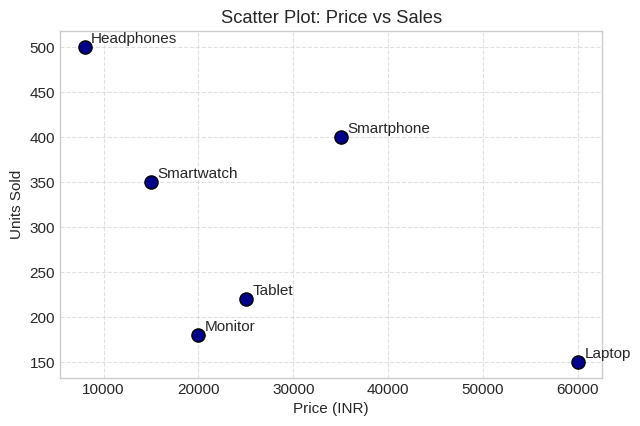

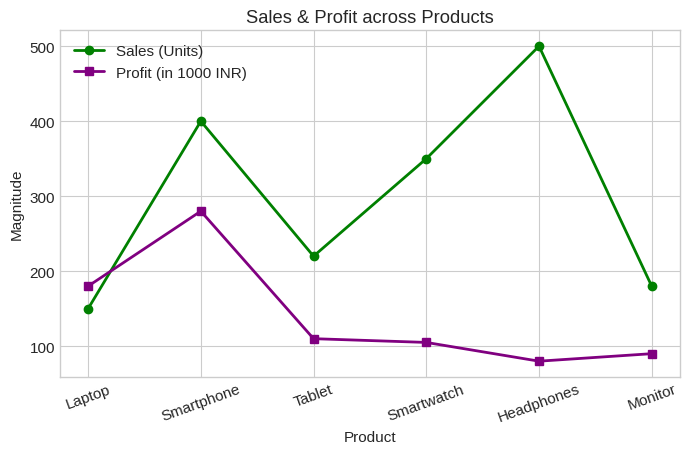

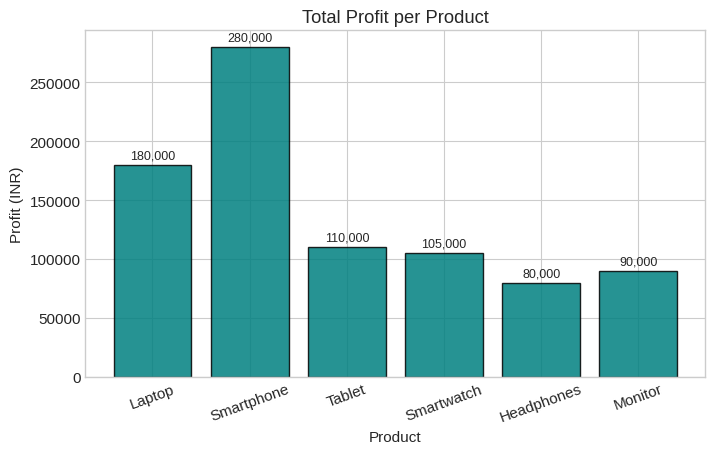

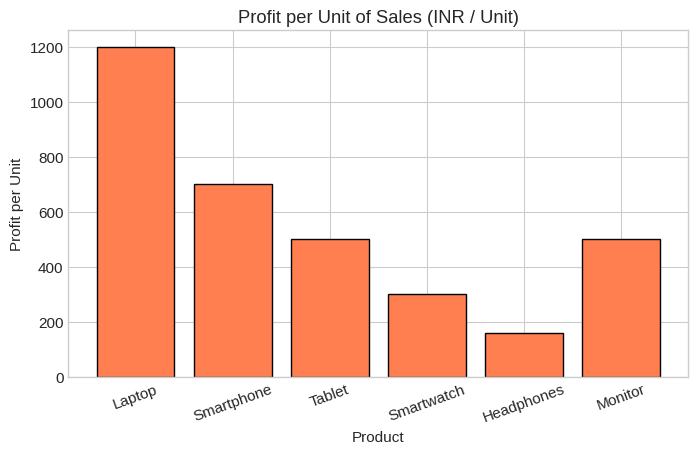

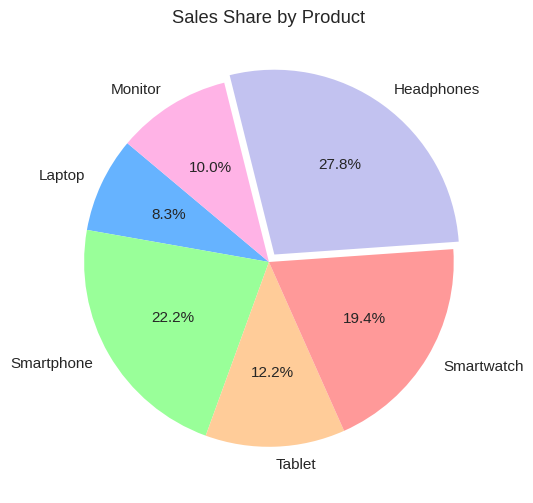

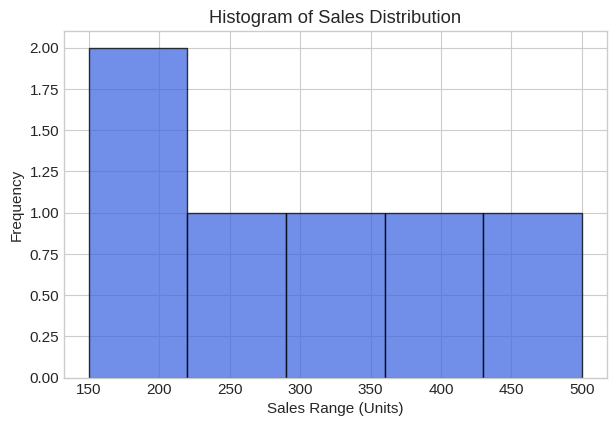

In [18]:
# 1. Scatter Plot: Price vs. Sales
plt.figure(figsize=(7, 4.5))
plt.scatter(df_products['Price'], df_products['Sales'], color='darkblue', s=90, edgecolors='black')
plt.title('Scatter Plot: Price vs Sales')
plt.xlabel('Price (INR)')
plt.ylabel('Units Sold')
for i, txt in enumerate(df_products['Products']):
    plt.annotate(txt, (df_products['Price'][i] + 700, df_products['Sales'][i] + 5))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 2. Line Plot: Sales and Profit
plt.figure(figsize=(8, 4.5))
plt.plot(df_products['Products'], df_products['Sales'], marker='o', linewidth=2, label='Sales (Units)', color='green')
plt.plot(df_products['Products'], df_products['Profit'] / 1000, marker='s', linewidth=2, label='Profit (in 1000 INR)', color='purple')
plt.title('Sales & Profit across Products')
plt.xlabel('Product')
plt.ylabel('Magnitude')
plt.legend()
plt.xticks(rotation=20)
plt.show()

# 3. Bar Chart: Profit per product
plt.figure(figsize=(8, 4.5))
bars = plt.bar(df_products['Products'], df_products['Profit'], color='teal', edgecolor='black', alpha=0.85)
plt.title('Total Profit per Product')
plt.xlabel('Product')
plt.ylabel('Profit (INR)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 3000, f'{int(yval):,}', ha='center', va='bottom', fontsize=9)
plt.xticks(rotation=20)
plt.show()

# 4. Bar Chart: Profit per Unit of Sales
df_products['Profit_per_Sale'] = df_products['Profit'] / df_products['Sales']
plt.figure(figsize=(8, 4.5))
plt.bar(df_products['Products'], df_products['Profit_per_Sale'], color='coral', edgecolor='black')
plt.title('Profit per Unit of Sales (INR / Unit)')
plt.xlabel('Product')
plt.ylabel('Profit per Unit')
plt.xticks(rotation=20)
plt.show()

# 5. Pie Chart: Sales Contribution
plt.figure(figsize=(6, 6))
plt.pie(df_products['Sales'], labels=df_products['Products'], autopct='%1.1f%%', startangle=140,
        colors=['#66b3ff','#99ff99','#ffcc99','#ff9999','#c2c2f0','#ffb3e6'],
        explode=[0.05 if p == 'Headphones' else 0 for p in df_products['Products']])
plt.title('Sales Share by Product')
plt.show()

# 6. Histogram: Distribution of Sales
plt.figure(figsize=(7, 4.5))
plt.hist(df_products['Sales'], bins=5, color='royalblue', edgecolor='black', alpha=0.75)
plt.title('Histogram of Sales Distribution')
plt.xlabel('Sales Range (Units)')
plt.ylabel('Frequency')
plt.show()


## 📌 Question 5: Synthetic Dataset Generation for Linear Regression
Generate 100 synthetic data points with 1 independent feature (`Hours_Studied`) and 1 dependent target (`Exam_Score`).
- Display first 5 rows and summary metrics
- Check missing values and dtypes
- Plot feature vs target scatter plot


Total Samples: 100
Dataset Shape: (100, 2)

First 5 Rows:
   Hours_Studied  Exam_Score
0           4.37       58.80
1           9.56       90.77
2           7.59       79.73
3           6.39       62.58
4           2.40       44.64

Data Types & Missing Values:
                 dtype  nulls
Hours_Studied  float64      0
Exam_Score     float64      0

Descriptive Statistics:
       Hours_Studied  Exam_Score
count     100.000000  100.000000
mean        5.232100   64.000800
std         2.677397   17.272178
min         1.050000   35.010000
25%         2.735000   49.467500
50%         5.175000   62.115000
75%         7.575000   79.407500
max         9.880000   97.750000


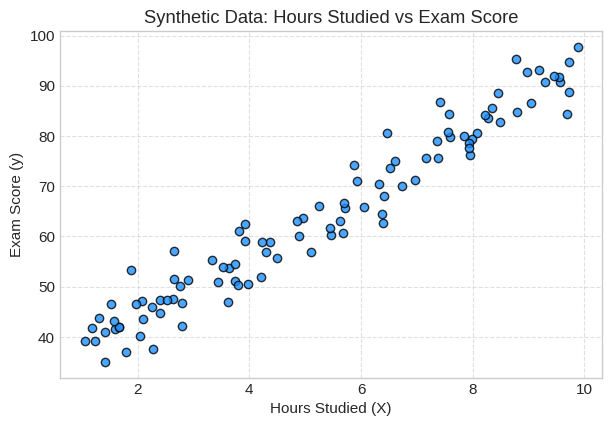

In [19]:
np.random.seed(42)
hours_studied = np.random.uniform(1.0, 10.0, 100)
noise = np.random.normal(0, 4.5, 100)
exam_scores = 6.5 * hours_studied + 30 + noise

df_synthetic = pd.DataFrame({
    'Hours_Studied': np.round(hours_studied, 2),
    'Exam_Score': np.round(exam_scores, 2)
})

print("Total Samples:", len(df_synthetic))
print("Dataset Shape:", df_synthetic.shape)
print("\nFirst 5 Rows:")
print(df_synthetic.head())

print("\nData Types & Missing Values:")
print(pd.DataFrame({'dtype': df_synthetic.dtypes, 'nulls': df_synthetic.isnull().sum()}))

print("\nDescriptive Statistics:")
print(df_synthetic.describe())

plt.figure(figsize=(7, 4.5))
plt.scatter(df_synthetic['Hours_Studied'], df_synthetic['Exam_Score'], color='dodgerblue', edgecolors='black', alpha=0.8)
plt.title('Synthetic Data: Hours Studied vs Exam Score')
plt.xlabel('Hours Studied (X)')
plt.ylabel('Exam Score (y)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


## 📌 Question 6: Simple Linear Regression Model
Implement Simple Linear Regression on the synthetic dataset:
1. Define 2D feature matrix $X$ and 1D target vector $y$
2. Train-test split (80% train, 20% test, `random_state=42`)
3. Train `LinearRegression()` model
4. Print slope ($\beta_1$) and intercept ($\beta_0$)
5. Predict on test set
6. Plot scatter points with fitted regression line


Train samples: 80, Test samples: 20
Model Equation: Exam_Score = 30.84 + 6.30 * Hours_Studied


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


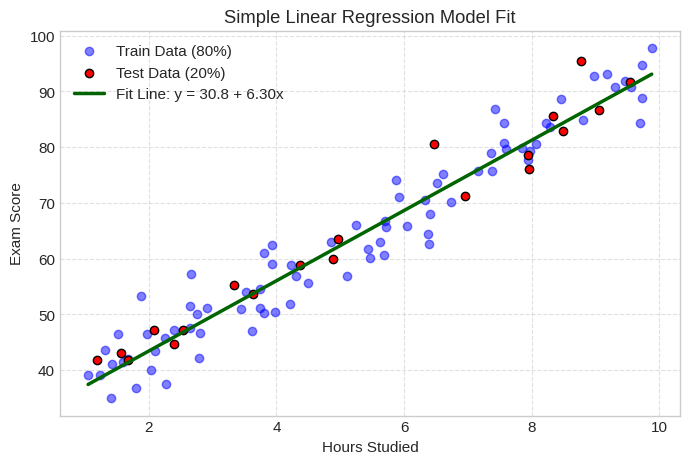

In [20]:
# 1. Prepare X (2D) and y (1D)
X = df_synthetic[['Hours_Studied']]
y = df_synthetic['Exam_Score']

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

# 3. Model training
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Coefficients
slope = model.coef_[0]
intercept = model.intercept_
print(f"Model Equation: Exam_Score = {intercept:.2f} + {slope:.2f} * Hours_Studied")

# 5. Predict on test set
y_test_pred = model.predict(X_test)

# 6. Plot fit line
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Train Data (80%)')
plt.scatter(X_test, y_test, color='red', edgecolors='black', label='Test Data (20%)')

x_span = np.linspace(X['Hours_Studied'].min(), X['Hours_Studied'].max(), 100).reshape(-1, 1)
y_span = model.predict(x_span)
plt.plot(x_span, y_span, color='darkgreen', linewidth=2.5, label=f'Fit Line: y = {intercept:.1f} + {slope:.2f}x')

plt.title('Simple Linear Regression Model Fit')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# ========================================================
# 🏠 PART 2: HOME ASSIGNMENTS (Questions 1 to 5)
# ========================================================


## 📌 Home Assignment 1: Student Marks Analysis using NumPy
Marks matrix for 4 students across 3 subjects:
```python
MARKS = np.array([
    [80, 75, 90],  # Student 1
    [65, 70, 72],  # Student 2
    [90, 88, 95],  # Student 3
    [55, 60, 58]   # Student 4
])
```
1. Calculate average for each student (`axis=1`)
2. Find student with highest average
3. Calculate average for each subject (`axis=0`)
4. Find subject with highest average
5. Identify students with average score > 75


In [21]:
MARKS = np.array([
    [80, 75, 90],
    [65, 70, 72],
    [90, 88, 95],
    [55, 60, 58]
])

print("Marks Matrix (Rows = Students, Cols = Subjects):")
print(MARKS)
print("-" * 55)

# 1. Average score for each student
student_avg = np.mean(MARKS, axis=1)
print("1. Student Averages:")
for i, avg in enumerate(student_avg):
    print(f"   Student {i+1}: {avg:.2f}")

# 2. Student with highest average
best_student = np.argmax(student_avg)
print(f"\n2. Highest Average Student: Student {best_student + 1} ({student_avg[best_student]:.2f})")

# 3. Average score for each subject
subject_avg = np.mean(MARKS, axis=0)
print("\n3. Subject Averages:")
for j, avg in enumerate(subject_avg):
    print(f"   Subject {j+1}: {avg:.2f}")

# 4. Subject with highest average
best_subject = np.argmax(subject_avg)
print(f"\n4. Highest Average Subject: Subject {best_subject + 1} ({subject_avg[best_subject]:.2f})")

# 5. Students with average > 75
qual_students = np.where(student_avg > 75)[0]
print("\n5. Students with Average > 75:")
for idx in qual_students:
    print(f"   Student {idx + 1} (Average: {student_avg[idx]:.2f})")


Marks Matrix (Rows = Students, Cols = Subjects):
[[80 75 90]
 [65 70 72]
 [90 88 95]
 [55 60 58]]
-------------------------------------------------------
1. Student Averages:
   Student 1: 81.67
   Student 2: 69.00
   Student 3: 91.00
   Student 4: 57.67

2. Highest Average Student: Student 3 (91.00)

3. Subject Averages:
   Subject 1: 72.50
   Subject 2: 73.25
   Subject 3: 78.75

4. Highest Average Subject: Subject 3 (78.75)

5. Students with Average > 75:
   Student 1 (Average: 81.67)
   Student 3 (Average: 91.00)


## 📌 Home Assignment 2: Multi-Variable Bubble Visualization
Using the product DataFrame:
- **X-axis**: `Price`
- **Y-axis**: `Sales`
- **Bubble Size**: Proportional to `Profit`
- **Bubble Color**: Color mapped to `Profit`
- **Labels**: Annotate each bubble with its Product name


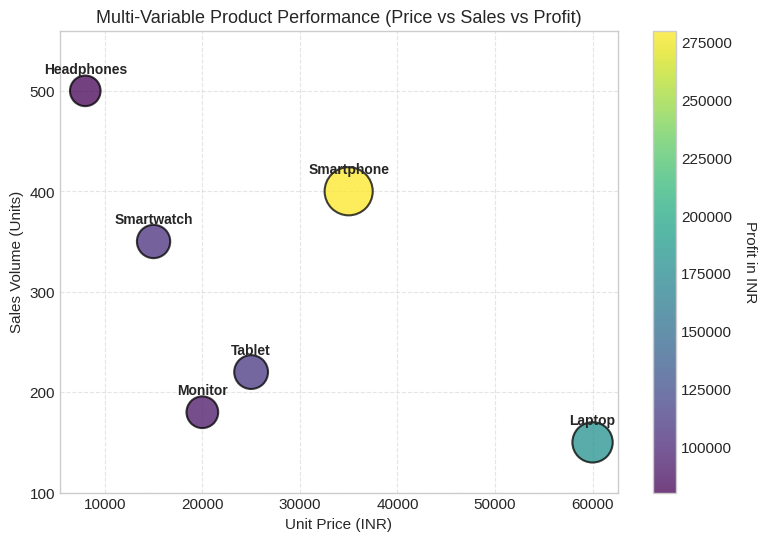

In [22]:
plt.figure(figsize=(9, 6))

size_scaled = (df_products['Profit'] / df_products['Profit'].max()) * 1000 + 200

scatter = plt.scatter(
    df_products['Price'],
    df_products['Sales'],
    s=size_scaled,
    c=df_products['Profit'],
    cmap='viridis',
    alpha=0.75,
    edgecolors='black',
    linewidth=1.5
)

cbar = plt.colorbar(scatter)
cbar.set_label('Profit in INR', rotation=270, labelpad=18)

for i, name in enumerate(df_products['Products']):
    plt.annotate(
        name,
        (df_products['Price'][i], df_products['Sales'][i] + 18),
        fontsize=10,
        fontweight='bold',
        ha='center'
    )

plt.title('Multi-Variable Product Performance (Price vs Sales vs Profit)', fontsize=13)
plt.xlabel('Unit Price (INR)', fontsize=11)
plt.ylabel('Sales Volume (Units)', fontsize=11)
plt.ylim(100, 560)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 📌 Home Assignment 3: External Dataset Loading (`Simple_House_Price.csv`)
Load `Simple_House_Price.csv` into a Pandas DataFrame and inspect properties.


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# External dataset path (ensure Simple_House_Price.csv is uploaded in Colab files panel)
csv_path = 'Simple_House_Price.csv'

try:
    df_house = pd.read_csv(csv_path)
    print("Dataset successfully loaded!")
    print("Shape:", df_house.shape)
    print("Columns:", list(df_house.columns))
    print("\nFirst 5 Rows:")
    display(df_house.head())

    print("\nData Types & Missing Values:")
    display(pd.DataFrame({'dtype': df_house.dtypes, 'nulls': df_house.isnull().sum()}))

    print("\nSummary Statistics:")
    display(df_house.describe())
except FileNotFoundError:
    print("❌ Error: 'Simple_House_Price.csv' not found!")
    print("👉 Please click the folder icon (📁) on the left sidebar of Colab and upload 'Simple_House_Price.csv'.")

Dataset successfully loaded!
Shape: (1000, 2)
Columns: ['Area_sqft', 'Price']

First 5 Rows:


,Area_sqft,Price
0,1828,116.17
1,2910,165.93
2,672,45.41
3,2540,154.88
4,1848,122.05



Data Types & Missing Values:


,dtype,nulls
Area_sqft,int64,0
Price,float64,0



Summary Statistics:


,Area_sqft,Price
count,1000.00000,1000.000000
mean,1710.09000,112.074290
std,733.20943,41.360021
min,501.00000,27.130000
25%,1077.75000,76.812500
50%,1713.00000,112.085000
75%,2334.25000,147.280000
max,2999.00000,207.450000


## 📌 Home Assignment 4: Mathematical Dataset Formulation
### Problem Specification:
A company collects records for **20,000 customers** with variables:
1. `Age` (Feature 1)
2. `Income` (Feature 2)
3. `Customer_Spending` (Target Variable)

### 📐 Mathematical Formulation:
1. **Total Number of Samples ($N$)**:
   $$N = 20{,}000$$

2. **Total Number of Features ($p$)**:
   $$p = 2 \quad (x_1 = \text{Age}, \; x_2 = \text{Income})$$

3. **Input Vector for the $i$-th customer ($\mathbf{x}_i$)**:
   $$\mathbf{x}_i = \begin{bmatrix} x_{i1} \\ x_{i2} \end{bmatrix} = \begin{bmatrix} \text{Age}_i \\ \text{Income}_i \end{bmatrix} \in \mathbb{R}^2$$

4. **Output / Target Value for the $i$-th customer ($y_i$)**:
   $$y_i = \text{Customer\_Spending}_i \in \mathbb{R}$$

5. **Design / Feature Matrix ($\mathbf{X}$)**:
   $$\mathbf{X} = \begin{bmatrix} \mathbf{x}_1^T \\ \mathbf{x}_2^T \\ \vdots \\ \mathbf{x}_N^T \end{bmatrix} = \begin{bmatrix} \text{Age}_1 & \text{Income}_1 \\ \text{Age}_2 & \text{Income}_2 \\ \vdots & \vdots \\ \text{Age}_{20000} & \text{Income}_{20000} \end{bmatrix} \in \mathbb{R}^{20000 \times 2}$$

6. **Target Vector ($\mathbf{y}$)**:
   $$\mathbf{y} = \begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_N \end{bmatrix} = \begin{bmatrix} \text{Customer\_Spending}_1 \\ \text{Customer\_Spending}_2 \\ \vdots \\ \text{Customer\_Spending}_{20000} \end{bmatrix} \in \mathbb{R}^{20000}$$

7. **Full Dataset Representation ($\mathcal{D}$)**:
   $$\mathcal{D} = \{ (\mathbf{x}_i, y_i) \}_{i=1}^{N} = \{ (\mathbf{x}_1, y_1), (\mathbf{x}_2, y_2), \dots, (\mathbf{x}_{20000}, y_{20000}) \}$$

8. **Hypothesis / Predictive Function**:
   $$\hat{y} = f(\mathbf{x}) = \beta_0 + \beta_1 (\text{Age}) + \beta_2 (\text{Income})$$

9. **Train-Test Split Dimensions (80% Train, 20% Test)**:
   - $N_{\text{train}} = 0.8 \times 20000 = 16{,}000$ samples $\implies \mathbf{X}_{\text{train}} \in \mathbb{R}^{16000 \times 2}, \; \mathbf{y}_{\text{train}} \in \mathbb{R}^{16000}$
   - $N_{\text{test}} = 0.2 \times 20000 = 4{,}000$ samples $\implies \mathbf{X}_{\text{test}} \in \mathbb{R}^{4000 \times 2}, \; \mathbf{y}_{\text{test}} \in \mathbb{R}^{4000}$


In [24]:
# Python verification of formal dimensions
N = 20000
p = 2
test_ratio = 0.2

N_train = int(N * (1 - test_ratio))
N_test = int(N * test_ratio)

print("Formalized Dimensions Summary:")
print(f"• Total Dataset Samples (N) : {N}")
print(f"• Total Input Features (p)   : {p}")
print(f"• Feature Matrix X shape     : ({N}, {p})")
print(f"• Target Vector y shape      : ({N},)")
print(f"• Training Matrix X_train    : ({N_train}, {p})")
print(f"• Testing Matrix X_test      : ({N_test}, {p})")


Formalized Dimensions Summary:
• Total Dataset Samples (N) : 20000
• Total Input Features (p)   : 2
• Feature Matrix X shape     : (20000, 2)
• Target Vector y shape      : (20000,)
• Training Matrix X_train    : (16000, 2)
• Testing Matrix X_test      : (4000, 2)


## 📌 Home Assignment 5: Linear Regression on `Simple_House_Price.csv` & Residual Error Analysis
Perform end-to-end regression modeling on house prices:
1. Plot scatter of `Area_sqft` vs `Price`
2. Split dataset into 80% train and 20% test
3. Train `LinearRegression()` model and display learned equation
4. Predict on both training and test sets
5. Compute residual errors: $e_i = y_i - \hat{y}_i$
6. Evaluate model with MAE, MSE, RMSE, and $R^2$ score
7. Plot regression line and residual diagnostics plot


Dataset Split: Train = 800 rows (80%), Test = 200 rows (20%)
Learned Equation: Price = 18.75 + 0.0546 * Area_sqft

--- Model Performance Metrics on Unseen Test Data ---
• Mean Absolute Error (MAE)     : 7.766
• Mean Squared Error (MSE)      : 103.128
• Root Mean Squared Error (RMSE): 10.155
• R-squared (R^2) Score         : 0.9410 (94.10% variance explained)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


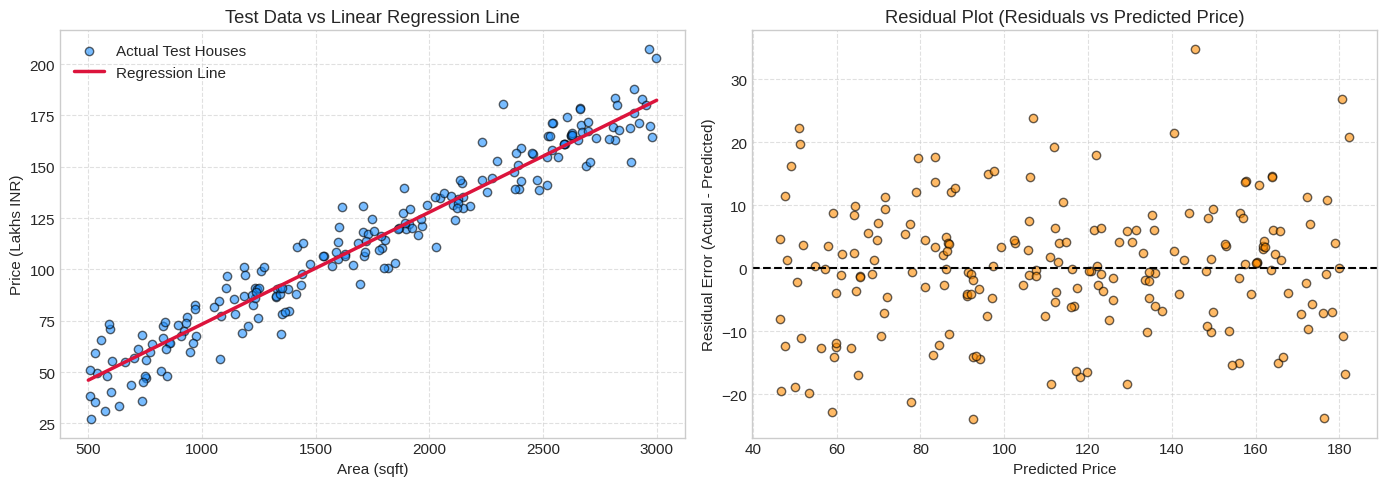

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    # 1. Feature and Target Extraction
    X_house = df_house[['Area_sqft']]
    y_house = df_house['Price']

    # 2. 80/20 Train-Test Split
    X_tr, X_te, y_tr, y_te = train_test_split(X_house, y_house, test_size=0.2, random_state=42)
    print(f"Dataset Split: Train = {X_tr.shape[0]} rows (80%), Test = {X_te.shape[0]} rows (20%)")

    # 3. Model Training
    house_model = LinearRegression()
    house_model.fit(X_tr, y_tr)

    b0 = house_model.intercept_
    b1 = house_model.coef_[0]
    print(f"Learned Equation: Price = {b0:.2f} + {b1:.4f} * Area_sqft")

    # 4. Predictions
    y_tr_pred = house_model.predict(X_tr)
    y_te_pred = house_model.predict(X_te)

    # 5. Residuals calculation
    residuals_test = y_te - y_te_pred

    # 6. Evaluation Metrics
    mae = mean_absolute_error(y_te, y_te_pred)
    mse = mean_squared_error(y_te, y_te_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_te, y_te_pred)

    print("\n--- Model Performance Metrics on Unseen Test Data ---")
    print(f"• Mean Absolute Error (MAE)     : {mae:.3f}")
    print(f"• Mean Squared Error (MSE)      : {mse:.3f}")
    print(f"• Root Mean Squared Error (RMSE): {rmse:.3f}")
    print(f"• R-squared (R^2) Score         : {r2:.4f} ({r2*100:.2f}% variance explained)")

    # 7. Diagnostic Visualizations
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Subplot 1: Regression Fit
    ax1.scatter(X_te, y_te, color='dodgerblue', alpha=0.6, edgecolors='k', label='Actual Test Houses')
    area_span = np.linspace(X_house['Area_sqft'].min(), X_house['Area_sqft'].max(), 200).reshape(-1, 1)
    ax1.plot(area_span, house_model.predict(area_span), color='crimson', linewidth=2.5, label='Regression Line')
    ax1.set_title('Test Data vs Linear Regression Line')
    ax1.set_xlabel('Area (sqft)')
    ax1.set_ylabel('Price (Lakhs INR)')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.6)

    # Subplot 2: Residual Plot
    ax2.scatter(y_te_pred, residuals_test, color='darkorange', alpha=0.6, edgecolors='k')
    ax2.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
    ax2.set_title('Residual Plot (Residuals vs Predicted Price)')
    ax2.set_xlabel('Predicted Price')
    ax2.set_ylabel('Residual Error (Actual - Predicted)')
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()
except NameError:
    print("❌ Error: Please ensure you have successfully uploaded the CSV and run Home Assignment 3 first to load 'df_house'.")